# Phase 4 (Optional) — OLID Benchmark

**Goal:** Add an additional external benchmark using OLID Level A (offensive vs non-offensive).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
for candidate in [ROOT, *ROOT.parents]:
    if (candidate / "src").is_dir() and (candidate / "requirements.txt").is_file():
        ROOT = candidate
        break
else:
    raise RuntimeError("Cannot find F21MP project root.")

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.phase4_olid.data.load_olid import load_olid_level_a, run_olid_benchmark

## 1) Inspect OLID split sizes

In [2]:
olid_train, olid_test = load_olid_level_a()
print('Train:', olid_train.shape)
print('Test:', olid_test.shape)
print('Train label counts:\n', olid_train['label_binary'].value_counts())
print('Test label counts:\n', olid_test['label_binary'].value_counts())

Train: (13240, 4)
Test: (860, 3)
Train label counts:
 label_binary
0    8840
1    4400
Name: count, dtype: int64
Test label counts:
 label_binary
0    620
1    240
Name: count, dtype: int64


## 2) Run OLID benchmark

Two evaluations are run:
- **zero_shot_phase1_a1**: reuse Phase 1 text-only model on OLID test
- **olid_in_domain_text_only**: train text-only model on OLID train, evaluate on OLID test

In [3]:
olid_out = run_olid_benchmark(save_outputs=True)
olid_summary = olid_out['summary']
olid_summary

/Users/pharshitha/Desktop/F21MP/.venv/lib/python3.13/site-packages/sklearn/base.py:463: InconsistentVersionWarning: Trying to unpickle estimator TfidfTransformer from version 1.6.1 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/Users/pharshitha/Desktop/F21MP/.venv/lib/python3.13/site-packages/sklearn/base.py:463: InconsistentVersionWarning: Trying to unpickle estimator TfidfVectorizer from version 1.6.1 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/Users/pharshitha/Desktop/F21MP/.venv/lib/python3.13/site-packages/sklearn/base.py:463: InconsistentVersionWarning: Trying to unpickle estimator Pipeline fro

,model,accuracy,precision,recall,f1,n_samples,n_positive,roc_auc
0,zero_shot_phase1_a1,0.716279,0.000000,0.000000,0.000000,860,240,0.501099
1,olid_in_domain_text_only,0.791860,0.640553,0.579167,0.608315,860,240,0.793219


## 3) Visual comparison

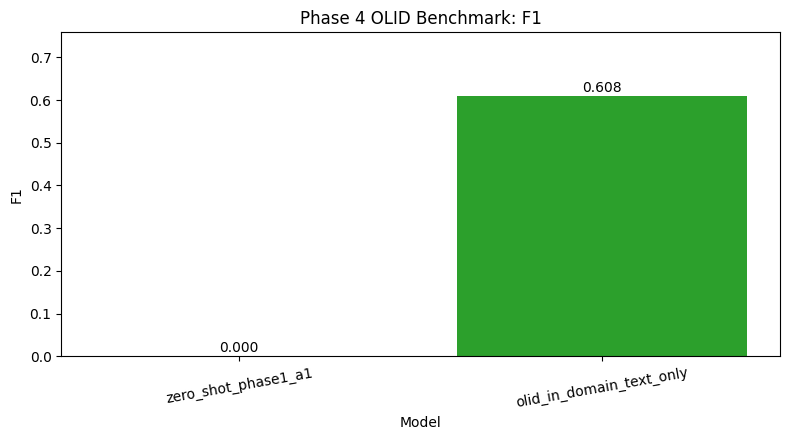

Saved: /Users/pharshitha/Desktop/F21MP/outputs/media/phase4_olid_f1.png


In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8,4.5))
ax.bar(olid_summary['model'], olid_summary['f1'], color=['#1f77b4','#2ca02c'])
ax.set_title('Phase 4 OLID Benchmark: F1')
ax.set_ylabel('F1')
ax.set_xlabel('Model')
for i,v in enumerate(olid_summary['f1']):
    ax.text(i, v+0.01, f'{v:.3f}', ha='center')
ax.set_ylim(0, min(1.05, max(olid_summary['f1'])+0.15))
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

out_plot = ROOT / 'outputs' / 'media' / 'phase4_olid_f1.png'
fig.savefig(out_plot, dpi=180, bbox_inches='tight')
print('Saved:', out_plot)

## 4) Phase 4 findings

- The **Phase 1 zero-shot baseline** typically performs poorly on OLID (low recall/F1), indicating limited direct transfer.
- A model trained on OLID itself performs substantially better, confirming domain mismatch between training corpora.
- This reinforces Phase 2 findings: cross-dataset transfer is limited without adaptation.

## 5) Saved outputs

- `outputs/results/phase4_olid_benchmark.json`
- `outputs/results/phase4_olid_benchmark_summary.csv`
- `outputs/media/phase4_olid_f1.png`

## 6) Final finding (Phase 4)

### Result summary
- **zero_shot_phase1_a1** (reuse Phase 1 text-only model on OLID test):
  - Accuracy: **0.716**
  - Precision: **0.000**
  - Recall: **0.000**
  - F1: **0.000**
  - ROC-AUC: **0.501**

- **olid_in_domain_text_only** (train on OLID train, test on OLID test):
  - Accuracy: **0.792**
  - Precision: **0.641**
  - Recall: **0.579**
  - F1: **0.608**
  - ROC-AUC: **0.793**

### Interpretation
The Phase 1 model does not transfer well to OLID in zero-shot mode (F1 = 0.000), but in-domain OLID training gives much better performance (F1 = 0.608). This confirms the same pattern observed in Phase 2: **cross-dataset transfer is limited due to domain and feature mismatch**, while dataset-specific training remains effective.

### Conclusion for Phase 4
Phase 4 reinforces the project-wide conclusion that relational/behavioural feature gains are strong in-domain, but external generalisation requires adaptation or retraining on the target domain.

## 7) Cross-reference: Phase 2 adaptation improvements

Phase 4 focuses on OLID benchmarking, but the project-level transfer story now also includes the new Phase 2 adaptation path:

- Small domain-adaptive fine-tune (text-only)
- Embedding-style extension (TF-IDF + SVD + Logistic Regression)

Latest Phase 2 reported metrics (Twitter subset):
- Domain-adaptive fine-tune: **F1 = 0.6334**, **ROC-AUC = 0.8028** (threshold = 0.40)
- Embedding extension: **F1 = 0.6441**, **ROC-AUC = 0.8172** (threshold = 0.30)

Use this as supporting evidence that limited target-domain adaptation improves transfer compared with strict zero-shot settings.
